## Imports, reading data etc

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
import joblib

In [194]:
df2906_1 = pd.read_csv('../data/labeled/no_plug/2906-1.csv')
df3006_1 = pd.read_csv('../data/labeled/no_plug/3006-1.csv')
df3006_2 = pd.read_csv('../data/labeled/no_plug/3006-2.csv')
df0404 = pd.read_csv('../data/labeled/no_plug/0404.csv')
df0712 = pd.read_csv('../data/labeled/no_plug/0712.csv')
df1703 = pd.read_csv('../data/labeled/no_plug/1703.csv')

df1803 = pd.read_csv('../data/labeled/partial_plug/1803.csv')
df1103 = pd.read_csv('../data/labeled/partial_plug/1103.csv')
df2503 = pd.read_csv('../data/labeled/partial_plug/2503.csv')
df2108_1 = pd.read_csv('../data/labeled/partial_plug/2108-1.csv')

df0709 = pd.read_csv('../data/labeled/plug/0709.csv')
df2106_2 = pd.read_csv('../data/labeled/plug/2106-2.csv')
df2108_2 = pd.read_csv('../data/labeled/plug/2108-2.csv')
df2906_2 = pd.read_csv('../data/labeled/plug/2906-2.csv')
df2906_3 = pd.read_csv('../data/labeled/plug/2906-3.csv')
df2906_4 = pd.read_csv('../data/labeled/plug/2906-4.csv')
df3006_3 = pd.read_csv('../data/labeled/plug/3006-3.csv')
df0612_2 = pd.read_csv('../data/labeled/plug/0612-2.csv')
df0612_3 = pd.read_csv('../data/labeled/plug/0612-3.csv')
df0707_1 = pd.read_csv('../data/labeled/plug/0707-1.csv')
df0707_2 = pd.read_csv('../data/labeled/plug/0707-2.csv')
df0707_4 = pd.read_csv('../data/labeled/plug/0707-4.csv')
df1112 = pd.read_csv('../data/labeled/plug/1112.csv')
df1310_2 = pd.read_csv('../data/labeled/plug/1310-2.csv')
df1310_3 = pd.read_csv('../data/labeled/plug/1310-3.csv')
df1407_1 = pd.read_csv('../data/labeled/plug/1407-1.csv')
df1407_2 = pd.read_csv('../data/labeled/plug/1407-2.csv')
df1407_3 = pd.read_csv('../data/labeled/plug/1407-3.csv')
df1407_4 = pd.read_csv('../data/labeled/plug/1407-4.csv')
df1503 = pd.read_csv('../data/labeled/plug/1503.csv')
df1811 = pd.read_csv('../data/labeled/plug/1811.csv')
df2701 = pd.read_csv('../data/labeled/plug/2701.csv')
df1003 = pd.read_csv('../data/labeled/plug/1003.csv')

In [195]:
no_plug_dfs = [df1703, df2906_1, df3006_1, df3006_2, df0404, df0712]

no_plug_names = ['1703', '2906-1', '3006-1', '3006-2', '0404', '0712']

plug_dfs = [df1003, df0709, df2106_2, df2108_2, df2906_2, df2906_3, df2906_4, 
            df3006_3, df0612_2, df0612_3, df0707_1, df0707_2, df0707_4, df1112, 
            df1310_2, df1310_3, df1407_1, df1407_2, df1407_3, df1407_4, df1503, df1811, df2701]

plug_names = ['1003', '0709', '2106-2', '2108-2', '2906-2', '2906-3', '2906-4',
           '3006-3', '0612-2', '0612-3', '0707-1', '0707-2', '0707-4', '1112',
           '1310-2', '1310-3', '1407-1', '1407-2', '1407-3', '1407-4', '1503', '1811', '2701']

partial_plug_dfs = [df1803, df1103, df2503, df2108_1]
partial_plug_names = ['1803', '1103', '2503', '2108-1']

In [196]:
no_plug_train_dfs = []

for df in no_plug_dfs:
    temp = df.copy()
    split_idx = int(len(temp) * 0.60)
    no_plug_train_dfs.append(
        temp.iloc[:split_idx].copy()
    )

In [197]:
for i in range(len(partial_plug_dfs)):
    if partial_plug_dfs[0].columns.all() != partial_plug_dfs[i].columns.all():
        print('mismatch!')
for i in range(len(no_plug_dfs)):
    if no_plug_dfs[0].columns.all() != no_plug_dfs[i].columns.all():
        print('mismatch!')
for i in range(len(plug_dfs)):
    if plug_dfs[0].columns.all() != plug_dfs[i].columns.all():
        print('mismatch!')

# Unsupervised Approach

In [198]:
def extract_features(df):
    temp = df.copy()
    
    baseline = temp.iloc[:60]

    temp['rel_tot_dp_change'] = temp['Total system DP'] / baseline['Total system DP'].median()
    temp['rel_ts_dp_change'] = temp['Differential pressure (Mean)'] / baseline['Differential pressure (Mean)'].median()
    temp['rel_p_ts_dp_change'] = temp['Pump to inlet DP'] / baseline['Pump to inlet DP'].median()
        
    return temp


få python til å gi modellen/formel ut


## Grid Search

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid

# ---------- Precompute features once ----------
feat_clean   = [extract_features(df)[0] for df in no_plug_train_dfs]
feat_no_plug = [extract_features(df)[0] for df in no_plug_dfs]
feat_plug    = [extract_features(df)[0] for df in plug_dfs]
all_feature_cols = extract_features(no_plug_train_dfs[0])[1]

train_ids = {id(df): i for i, df in enumerate(no_plug_train_dfs)}
e2t = [train_ids.get(id(df)) for df in no_plug_dfs]
print(f"{sum(t is not None for t in e2t)} of {len(e2t)} eval clean runs overlap with training")


# ---------- Helpers ----------
def fit_model(train_feats, p, seed):
    scaler = StandardScaler()
    X = scaler.fit_transform(pd.concat(train_feats)[p['features']])
    model = IsolationForest(
        n_estimators=p['n_estimators'],
        max_samples=p['max_samples'],
        max_features=p['max_features'],
        bootstrap=p['bootstrap'],
        contamination=p['contamination'],     # sets offset_, so 0 is the boundary
        random_state=seed,
        n_jobs=-1,
    ).fit(X)
    return model, scaler


def smoothed_scores(f, model, scaler, p):
    s = pd.Series(model.decision_function(scaler.transform(f[p['features']])))
    return s.rolling(p['smooth_window'], center=True).mean().fillna(s)


def run_min(f, model, scaler, p):
    return smoothed_scores(f, model, scaler, p).min()


# ---------- Evaluate: fixed threshold of 0, clean runs scored by models that never saw them ----------
def evaluate(p, seed=42, k=5):
    n_train = len(feat_clean)
    rng = np.random.RandomState(seed)
    folds = np.array_split(rng.permutation(n_train), k)
    fold_of = {t: i for i, fold in enumerate(folds) for t in fold}

    np_scores = [[] for _ in feat_no_plug]
    p_scores  = [[] for _ in feat_plug]

    for i in range(k):
        train = [feat_clean[j] for j in range(n_train) if fold_of[j] != i]
        model, scaler = fit_model(train, p, seed)

        for e, f in enumerate(feat_no_plug):
            t = e2t[e]
            if t is None or fold_of[t] == i:          # only models that did NOT train on this run
                np_scores[e].append(run_min(f, model, scaler, p))
        for e, f in enumerate(feat_plug):
            p_scores[e].append(run_min(f, model, scaler, p))

    np_min = np.array([np.mean(s) for s in np_scores])
    p_min  = np.array([np.mean(s) for s in p_scores])

    fp = int((np_min < 0).sum())                      # clean runs crossing 0 (want 0)
    tp = int((p_min < 0).sum())                       # plug runs crossing 0 (want max)
    clean_margin = float(np_min.min())                # how far the lowest clean run stays ABOVE 0
    plug_depth = float(-p_min[p_min < 0].mean()) if tp else 0.0   # how far detected plugs go BELOW 0

    return dict(fp=fp, tp=tp, tpr=tp / len(p_min),
                clean_margin=clean_margin, plug_depth=plug_depth)

0 of 6 eval clean runs overlap with training


In [162]:
param_space = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_samples': [0.25, 0.5, 0.75, 1.0],
    'max_features': [1.0],
    'bootstrap': [False],
    'contamination': [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05],
    'smooth_window': [5, 10],
    'features': [all_feature_cols],      
}

configs, rows = [], []
for p in ParameterGrid(param_space):
    r = evaluate(p, seed=42)
    configs.append(p)
    rows.append({**{k: v for k, v in p.items() if k != 'features'}, **r})

res = pd.DataFrame(rows)
ranked = res.sort_values(['fp', 'tp', 'clean_margin'], ascending=[True, False, False])
print(ranked.head(10).round(4))

    bootstrap  contamination  max_features  max_samples  n_estimators  \
49      False         0.0010           1.0         0.25           300   
45      False         0.0010           1.0         0.25           200   
24      False         0.0005           1.0         0.75           200   
22      False         0.0005           1.0         0.75           150   
28      False         0.0005           1.0         0.75           300   
26      False         0.0005           1.0         0.75           250   
20      False         0.0005           1.0         0.75           100   
32      False         0.0005           1.0         1.00           150   
30      False         0.0005           1.0         1.00           100   
51      False         0.0010           1.0         0.50           100   

    smooth_window  fp  tp    tpr  clean_margin  plug_depth  
49             10   0  21  0.913        0.0184      0.0704  
45             10   0  21  0.913        0.0183      0.0714  
24           

In [163]:
def seed_check(p, seeds=range(5)):
    out = pd.DataFrame([evaluate(p, seed=s) for s in seeds])
    return dict(fp_max=out.fp.max(), tp_mean=out.tp.mean(), tp_std=out.tp.std(),
                margin_mean=out.clean_margin.mean())

summary = []
for idx in ranked.index[:10]:
    summary.append({'idx': idx, **seed_check(configs[idx])})
summary = (pd.DataFrame(summary)
           .sort_values(['fp_max', 'tp_mean', 'margin_mean'], ascending=[True, False, False]))
print(summary.round(3))

best_params = configs[int(summary.iloc[0]['idx'])]
print(best_params)

   idx  fp_max  tp_mean  tp_std  margin_mean
4   28       0     21.0   0.000        0.006
0   49       0     20.4   0.548        0.023
1   45       0     20.2   0.447        0.025
5   26       1     21.0   0.000        0.007
2   24       1     21.0   0.000        0.006
3   22       1     21.0   0.000        0.005
6   20       1     21.0   0.000        0.004
7   32       1     21.0   0.000        0.001
8   30       1     21.0   0.000        0.000
9   51       1     21.0   0.000       -0.004
{'bootstrap': False, 'contamination': 0.0005, 'features': ['rel_tot_dp_change', 'rel_ts_dp_change', 'rel_p_ts_dp_change', 'Relative_Ratio_Dev'], 'max_features': 1.0, 'max_samples': 0.75, 'n_estimators': 300, 'smooth_window': 5}


## Model training

In [199]:
feature_cols = ['rel_tot_dp_change', 'rel_ts_dp_change', 'rel_p_ts_dp_change', 'Relative_Ratio_Dev']
processed_no_plug = [extract_features(df) for df in no_plug_train_dfs]

all_clean_data = pd.concat(processed_no_plug)
scaler = StandardScaler()
X_clean_scaled = scaler.fit_transform(all_clean_data[feature_cols])

iso_model = IsolationForest(
    n_estimators=300,
    max_samples=0.75,
    contamination=0.0005,
    random_state=42,
)
iso_model.fit(X_clean_scaled)

IsolationForest(contamination=0.0005, max_samples=0.75, n_estimators=300,
                random_state=42)

In [204]:
iso_model.get_params()

{'bootstrap': False,
 'contamination': 0.0005,
 'max_features': 1.0,
 'max_samples': 0.75,
 'n_estimators': 300,
 'n_jobs': None,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

In [200]:
joblib.dump(scaler, '../models/new_anomaly_scaler.joblib')
joblib.dump(iso_model, '../models/new_anomaly_isolation_forest.joblib')

['../models/new_anomaly_isolation_forest.joblib']

In [201]:
def apply_anomaly_scoring(df_list, model, scaler, features):
    scored_list = []
    for df in df_list:
        temp = extract_features(df)
        
        X_scaled = scaler.transform(temp[features])
        
        temp['anomaly_score'] = model.decision_function(X_scaled)
        
        temp['smooth_score'] = temp['anomaly_score'].rolling(window=5, center=True).mean().fillna(temp['anomaly_score'])
        
        scored_list.append(temp)
    return scored_list

scored_no_plug = apply_anomaly_scoring(no_plug_dfs, iso_model, scaler, feature_cols)
scored_plug = apply_anomaly_scoring(plug_dfs, iso_model, scaler, feature_cols)
scored_partial = apply_anomaly_scoring(partial_plug_dfs, iso_model, scaler, feature_cols)

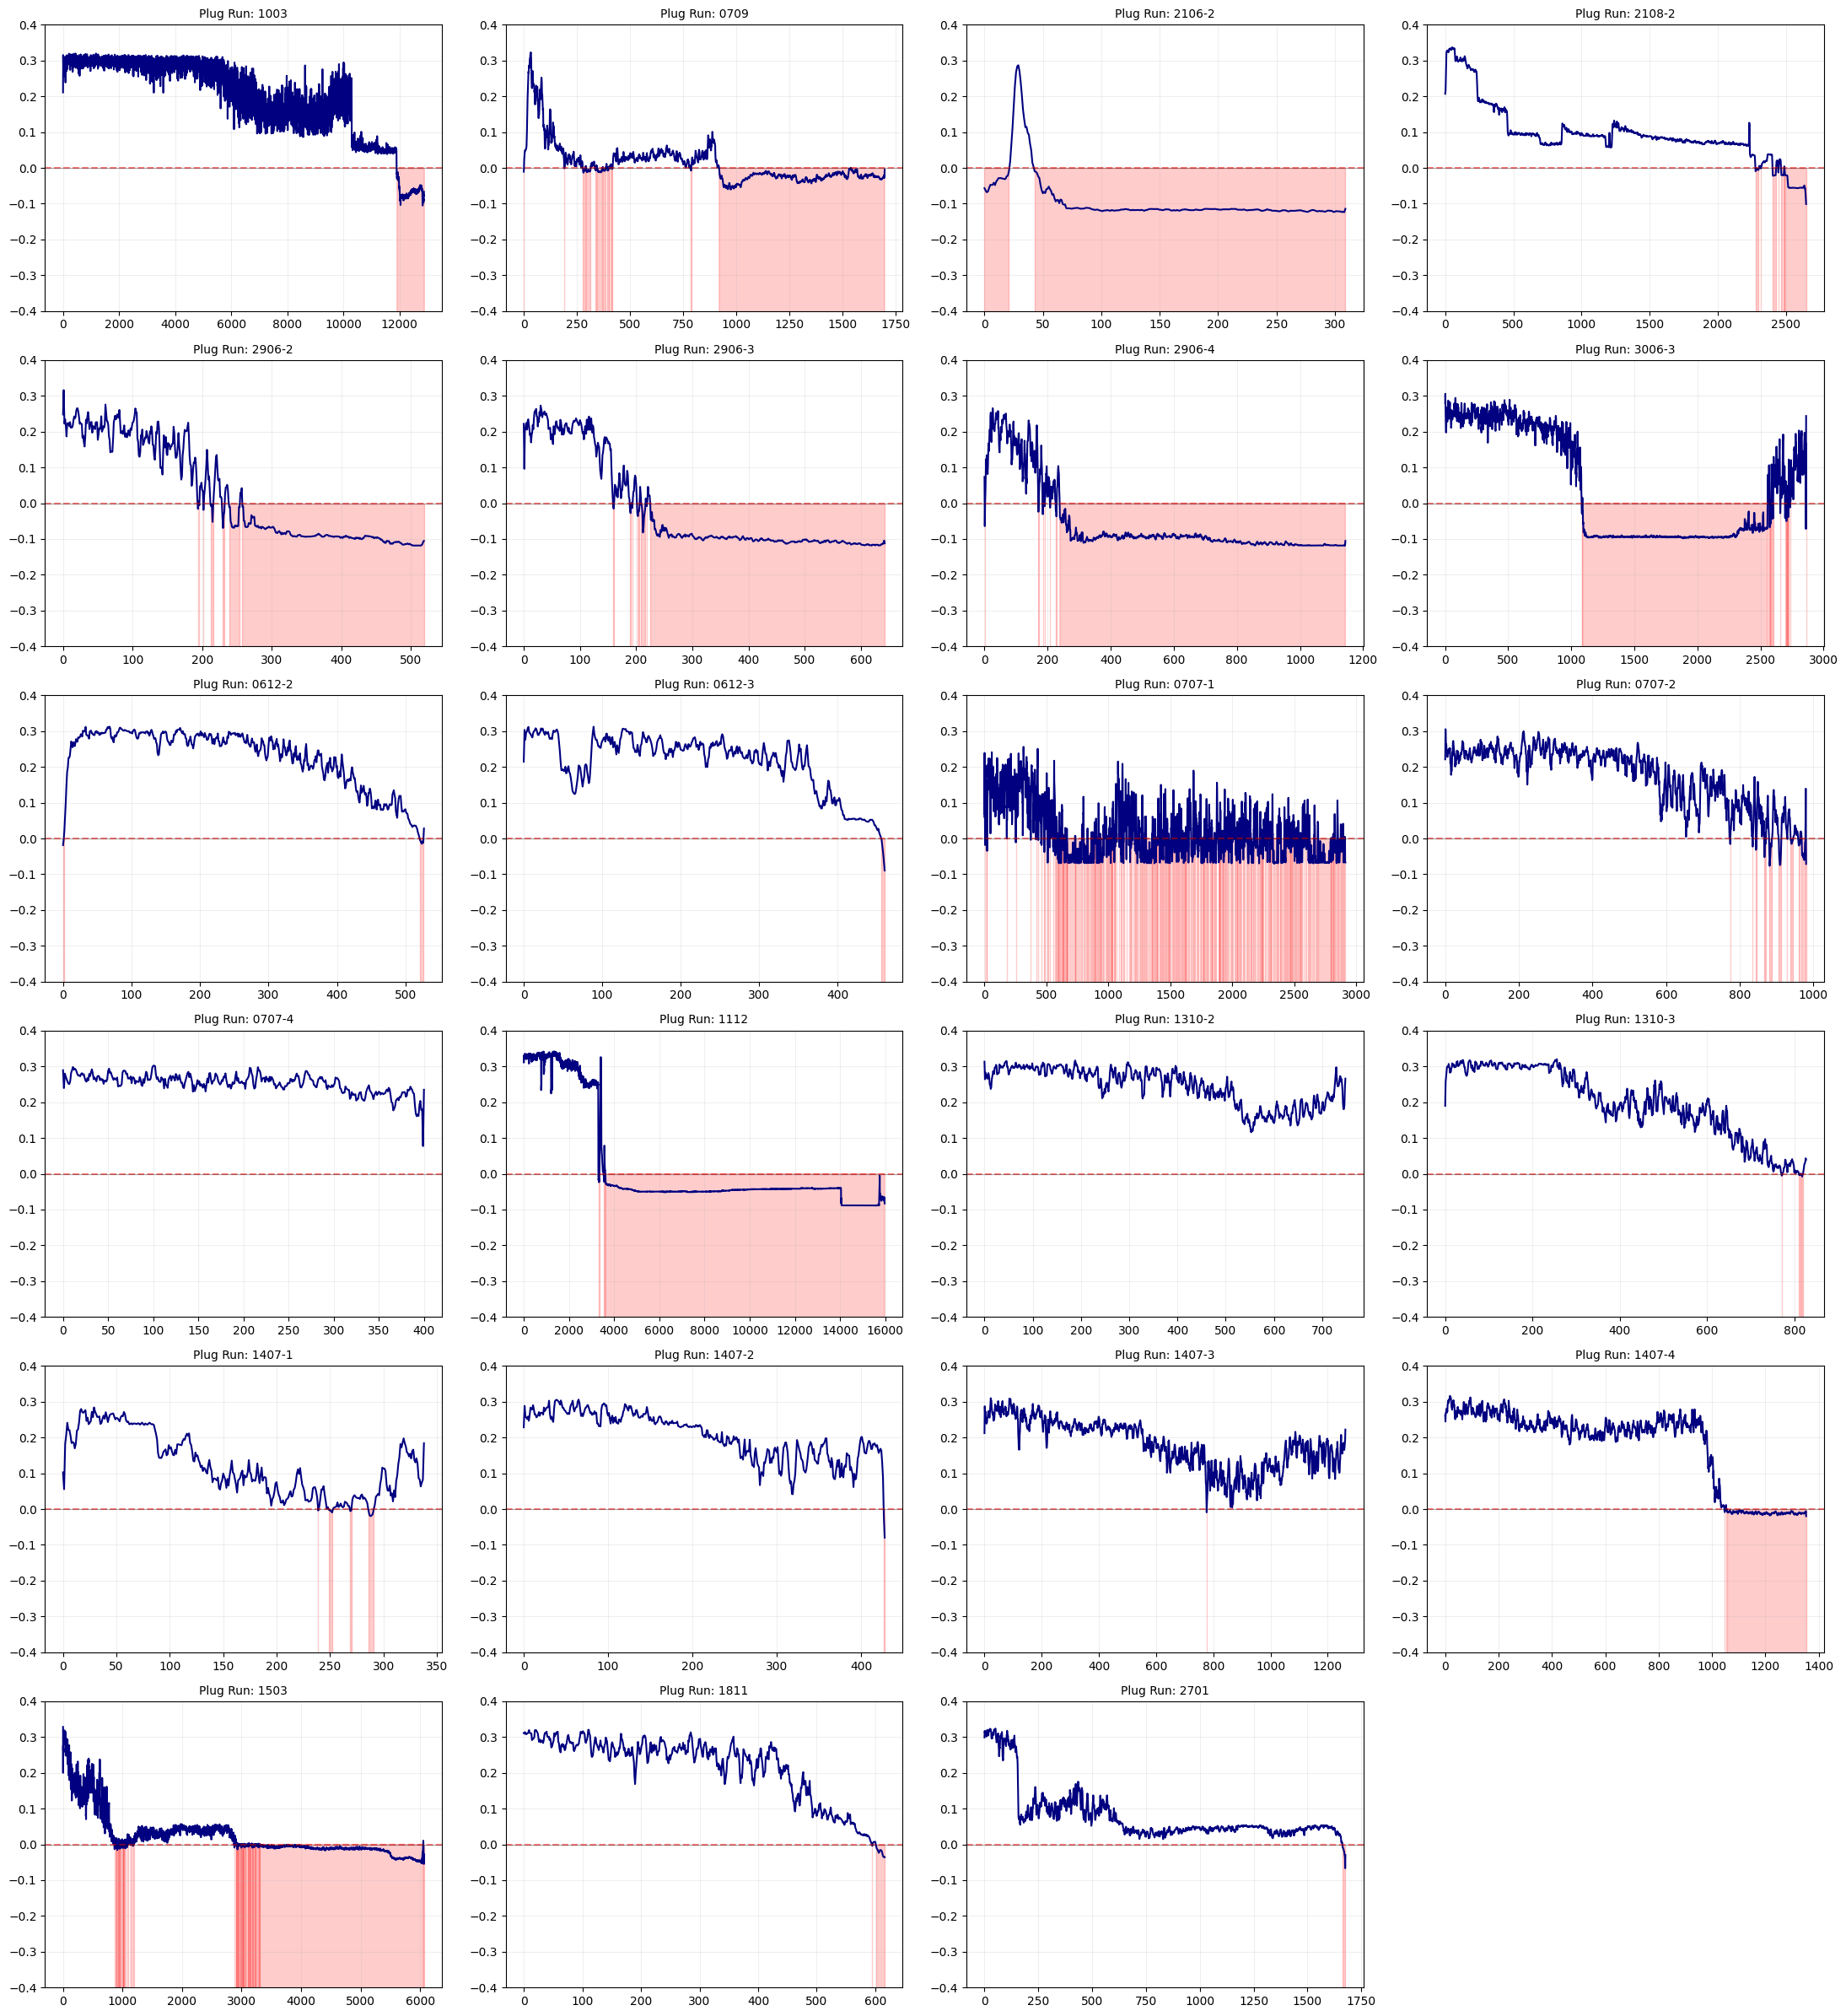

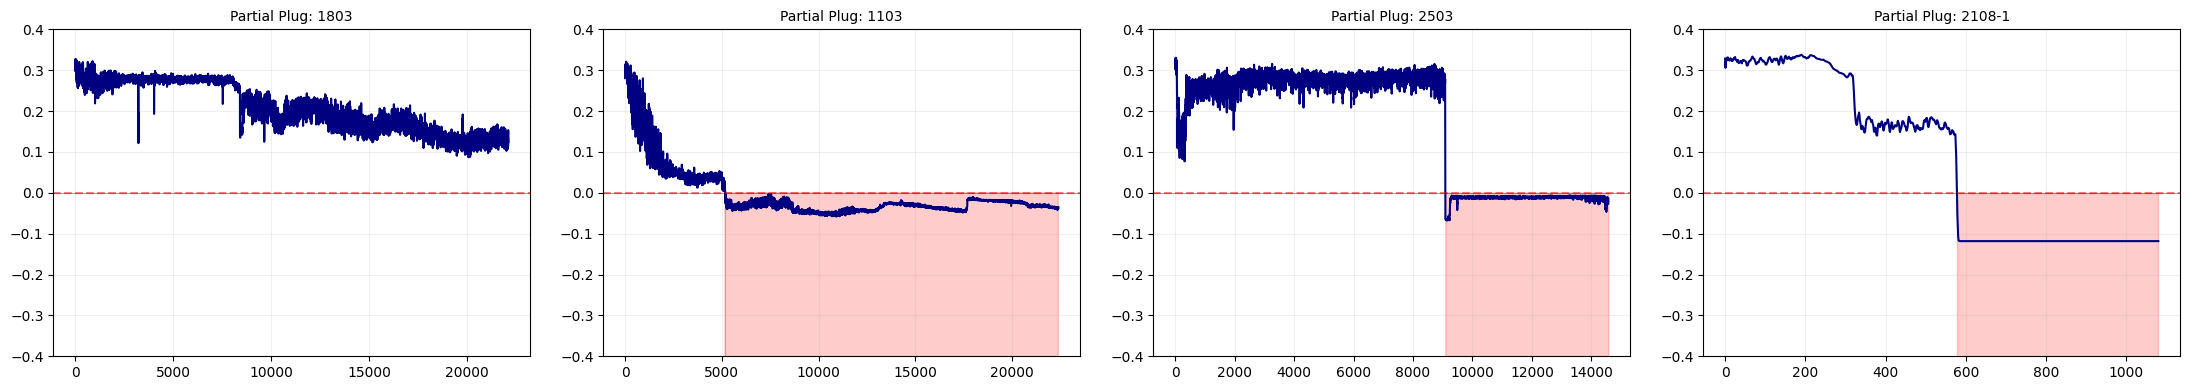

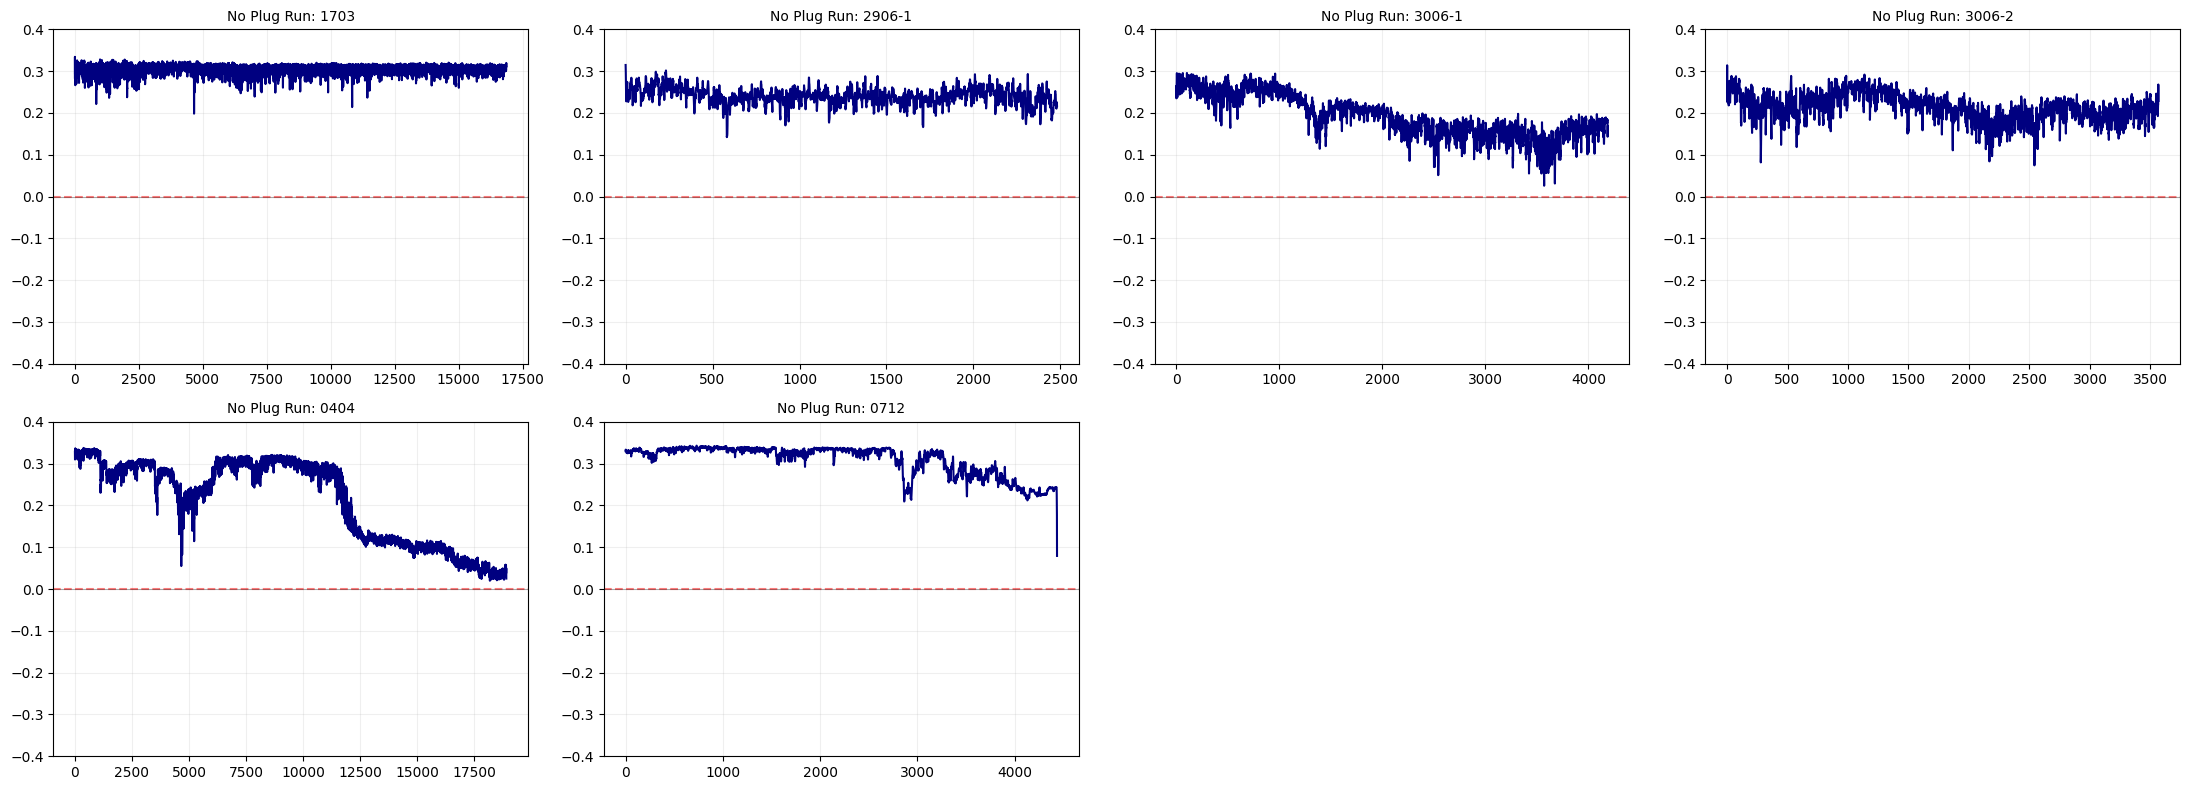

In [202]:
def plot_anomaly_results(df_list, names, title_prefix, threshold=-0.0):
    cols = 4
    rows = math.ceil(len(df_list) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(22, 4 * rows))
    axes = axes.flatten()

    for i, df in enumerate(df_list):
        ax = axes[i]
        
        ax.plot(df['run_specific_time_s'], df['smooth_score'], color='navy', label='Anomaly Score')
        
        ax.fill_between(df['run_specific_time_s'], -0.5, threshold, 
                        where=(df['smooth_score'] < threshold), color='red', alpha=0.2)
        
        ax.axhline(y=threshold, color='red', linestyle='--', alpha=0.5)
        ax.axhline(y=0, color='black', linewidth=0.8, alpha=0.3) 
        
        ax.set_title(f"{title_prefix}: {names[i]}", fontsize=10)
        ax.set_ylim([-0.4, 0.4]) 
        ax.grid(True, alpha=0.2)


    for j in range(i + 1, len(axes)): axes[j].axis('off')
    plt.tight_layout()
    plt.show()

plot_anomaly_results(scored_plug, plug_names, "Plug Run")

plot_anomaly_results(scored_partial, partial_plug_names, "Partial Plug")

plot_anomaly_results(scored_no_plug, no_plug_names, "No Plug Run")

In [203]:
for i, df in enumerate(scored_plug):
    df.to_csv(f'../data/labeledAndAnomaly/plug/{plug_names[i]}.csv', index=False)

for i, df in enumerate(scored_no_plug):
    df.to_csv(f'../data/labeledAndAnomaly/no_plug/{no_plug_names[i]}.csv', index=False)

for i, df in enumerate(scored_partial):
    df.to_csv(f'../data/labeledAndAnomaly/partial_plug/{partial_plug_names[i]}.csv', index=False)

In [209]:
average_describe = pd.concat([
    df[['rel_tot_dp_change', 'rel_ts_dp_change', 'rel_p_ts_dp_change', 'Relative_Ratio_Dev', 'anomaly_score']].describe()
    for df in scored_no_plug + scored_partial + scored_plug
]).groupby(level=0, sort=False).mean()

display(average_describe)

,rel_tot_dp_change,rel_ts_dp_change,rel_p_ts_dp_change,Relative_Ratio_Dev,anomaly_score
count,5087.242424,5087.242424,5087.242424,5087.242424,5087.242424
mean,1.038294,1.385261,1.025958,0.515600,0.135811
std,0.073282,0.440350,0.076866,0.339765,0.091932
min,0.866030,0.380902,0.888299,0.001074,-0.056114
25%,0.993928,1.058878,0.979170,0.238284,0.068867
50%,1.028891,1.330584,0.994201,0.496671,0.133644
75%,1.077872,1.724164,1.066146,0.770810,0.196567
max,1.276944,2.751432,1.294390,1.832582,0.336346
